<h1 align='center' style='color:purple'>Clustering With K Means - Python Tutorial</h1>

## 3. The K-Means algorithm and its objective function

### 3.1 Steps

1. **Choose K** – the number of clusters.
2. **Initialise** K centroids $\mu_1, \dots, \mu_K$ (randomly picked points, or the smarter *k-means++* in scikit-learn).
3. **Assignment step** – give each point $x_i$ to the closest centroid using **Euclidean distance**:
$$d(x, \mu) = \sqrt{(x_1-\mu_1)^2 + (x_2-\mu_2)^2 + \dots}$$
$$c_i = \arg\min_{k}\; d(x_i, \mu_k)$$
4. **Update step** – move every centroid to the **mean** of the points assigned to it:
$$\mu_k = \frac{1}{|C_k|}\sum_{x_i \in C_k} x_i$$
5. **Repeat** steps 3–4 until the assignments (or centroids) stop changing — this is **convergence**.

### 3.2 What K-Means is minimising

K-Means minimises the **Within-Cluster Sum of Squares (WCSS)**, which scikit-learn calls **`inertia_`**:

$$\text{WCSS} = \sum_{k=1}^{K}\;\sum_{x_i \in C_k} \lVert x_i - \mu_k \rVert^2$$

* Each assignment step and each update step can only **decrease (or keep)** the WCSS ⇒ the algorithm is guaranteed to converge.
* But it converges to a **local** minimum, which depends on the starting centroids. That is why scikit-learn runs it several times (`n_init`) and keeps the best result.

## 4. Numerical worked example (by hand) ✍️

Let's cluster **7 points** into **K = 2** clusters completely by hand, and then let Python confirm every number.

| Point | x | y |
|---|---|---|
| A | 1.0 | 1.0 |
| B | 1.5 | 2.0 |
| C | 3.0 | 4.0 |
| D | 5.0 | 7.0 |
| E | 3.5 | 5.0 |
| F | 4.5 | 5.0 |
| G | 3.5 | 4.5 |

**Initial centroids** (chosen as two far-apart points): $\mu_1 = A = (1, 1)$ and $\mu_2 = D = (5, 7)$.

---

### 🔁 Iteration 1

**Assignment step.** Example calculation for point **B (1.5, 2)**:

$$d(B,\mu_1) = \sqrt{(1.5-1)^2 + (2-1)^2} = \sqrt{0.25+1} = \sqrt{1.25} = 1.118$$
$$d(B,\mu_2) = \sqrt{(1.5-5)^2 + (2-7)^2} = \sqrt{12.25+25} = \sqrt{37.25} = 6.103$$

$1.118 < 6.103$ ⇒ **B → Cluster 1**. Doing this for every point:

| Point | d to μ₁ (1, 1) | d to μ₂ (5, 7) | Assigned to |
|---|---|---|---|
| A | 0.000 | 7.211 | **C1** |
| B | 1.118 | 6.103 | **C1** |
| C | 3.606 | 3.606 | **C1** *(tie → first centroid)* |
| D | 7.211 | 0.000 | **C2** |
| E | 4.717 | 2.500 | **C2** |
| F | 5.315 | 2.062 | **C2** |
| G | 4.301 | 2.915 | **C2** |

> ⚠️ Point **C** is *exactly* the same distance from both centroids. By convention (and in NumPy's `argmin`) ties go to the **first** centroid.

**Update step.**

$$\mu_1 = \text{mean}(A,B,C) = \left(\tfrac{1+1.5+3}{3},\; \tfrac{1+2+4}{3}\right) = (1.833,\; 2.333)$$
$$\mu_2 = \text{mean}(D,E,F,G) = \left(\tfrac{5+3.5+4.5+3.5}{4},\; \tfrac{7+5+5+4.5}{4}\right) = (4.125,\; 5.375)$$

---

### 🔁 Iteration 2

| Point | d to μ₁ (1.833, 2.333) | d to μ₂ (4.125, 5.375) | Assigned to |
|---|---|---|---|
| A | 1.572 | 5.376 | C1 |
| B | 0.471 | 4.276 | C1 |
| C | 2.034 | **1.777** | **C2** ⬅ *changed!* |
| D | 5.640 | 1.846 | C2 |
| E | 3.145 | 0.729 | C2 |
| F | 3.771 | 0.530 | C2 |
| G | 2.734 | 1.075 | C2 |

Point **C** has moved to Cluster 2. **Update step:**

$$\mu_1 = \text{mean}(A,B) = (1.25,\; 1.5)$$
$$\mu_2 = \text{mean}(C,D,E,F,G) = \left(\tfrac{3+5+3.5+4.5+3.5}{5},\; \tfrac{4+7+5+5+4.5}{5}\right) = (3.9,\; 5.1)$$

---

### 🔁 Iteration 3

| Point | d to μ₁ (1.25, 1.5) | d to μ₂ (3.9, 5.1) | Assigned to |
|---|---|---|---|
| A | 0.559 | 5.022 | C1 |
| B | 0.559 | 3.920 | C1 |
| C | 3.052 | 1.421 | C2 |
| D | 6.657 | 2.195 | C2 |
| E | 4.161 | 0.412 | C2 |
| F | 4.776 | 0.608 | C2 |
| G | 3.750 | 0.721 | C2 |

No point changed cluster ⇒ the centroids stay at $(1.25, 1.5)$ and $(3.9, 5.1)$ ⇒ **converged ✅**

**Final clusters:** C1 = {A, B}, C2 = {C, D, E, F, G}

### 📉 WCSS at the end

$$\text{WCSS} = \underbrace{(0.25^2+0.5^2) + (0.25^2+0.5^2)}_{\text{C1: } A, B = 0.625} + \underbrace{(0.9^2+1.1^2) + (1.1^2+1.9^2) + (0.4^2+0.1^2) + (0.6^2+0.1^2) + (0.4^2+0.6^2)}_{\text{C2} = 7.9} = 8.525$$

WCSS went **33.25 → 11.23 → 8.525** across the iterations (computed with the centroids used in each assignment step) — it never increases.

Now let's check all of this with code 👇

## 5. Evaluation metrics for clustering 📏

Because clustering has **no ground-truth labels**, we can't use accuracy. Instead we use:

* **Internal metrics** – judge the clusters using only the data (compactness & separation).
* **External metrics** – compare to true labels, *only if* they happen to be available (e.g. for teaching datasets like Iris).

### 5.1 Internal metrics

| Metric | Formula / idea | Range | Better when | In sklearn |
|---|---|---|---|---|
| **WCSS / Inertia** | $\sum_k \sum_{x \in C_k}\lVert x-\mu_k\rVert^2$ — compactness | $[0, \infty)$ | **Lower** (but *always* falls as K grows) | `km.inertia_` |
| **Silhouette score** | $s(i) = \dfrac{b(i) - a(i)}{\max\{a(i), b(i)\}}$ averaged over all points | $[-1, 1]$ | **Higher** (≈1 great, ≈0 overlapping, <0 wrong cluster) | `silhouette_score` |


In the silhouette:
* $a(i)$ = average distance from point $i$ to the **other points in its own cluster** (how tight its cluster is),
* $b(i)$ = average distance from point $i$ to the points of the **nearest other cluster** (how far the neighbours are).

### 5.2 External metrics (need true labels)

| Metric | Range | Meaning |
|---|---|---|
| **Adjusted Rand Index (ARI)** | $[-1, 1]$ | 1 = perfect match with true labels, ≈0 = random labelling |
| **Normalized Mutual Information (NMI)** | $[0, 1]$ | 1 = clusters carry exactly the same information as the labels |

Both ignore the *names* of the clusters — cluster "0" vs "1" swapped still scores 1.0.

---

### ✍️ Hand calculation: silhouette of point A in the worked example

Final clusters: C1 = {A, B}, C2 = {C, D, E, F, G}.

**a(A)** – A's own cluster contains only B:
$$a(A) = d(A,B) = 1.118$$

**b(A)** – average distance from A to every point of C2:
$$b(A) = \frac{d(A,C)+d(A,D)+d(A,E)+d(A,F)+d(A,G)}{5} = \frac{3.606+7.211+4.717+5.315+4.301}{5} = \frac{25.150}{5} = 5.030$$

$$s(A) = \frac{5.030 - 1.118}{\max(1.118,\; 5.030)} = \frac{3.912}{5.030} = \mathbf{0.778}$$

A is **well inside** its cluster (close to 1). Let's verify, and compute all metrics for the worked example:

In [1]:
from sklearn.cluster import KMeans
import pandas as pd
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from matplotlib import pyplot as plt
from sklearn.metrics import silhouette_score, adjusted_rand_score, normalized_mutual_info_score
import numpy as np

%matplotlib inline

# Load the data set

In [2]:
# Load the income dataset
df = pd.read_csv("income - income.csv")

print("Dataset shape:", df.shape)
display(df.head())
print("\\nDataset information:")
df.info()

Dataset shape: (22, 3)


,Name,Age,Income($)
0,Rob,27,70000
1,Michael,29,90000
2,Mohan,29,61000
3,Ismail,28,60000
4,Kory,42,150000


\nDataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22 entries, 0 to 21
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   Name       22 non-null     object
 1   Age        22 non-null     int64 
 2   Income($)  22 non-null     int64 
dtypes: int64(2), object(1)
memory usage: 660.0+ bytes


# Plot the scater plot

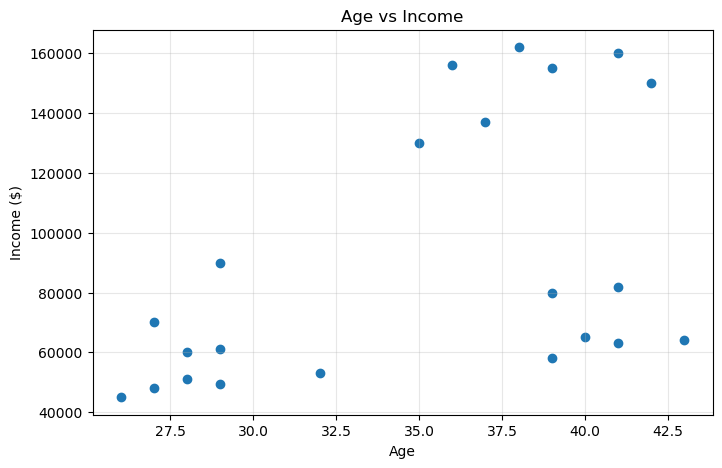

In [3]:
# Plot the scatter plot of Age vs Income
plt.figure(figsize=(8, 5))
plt.scatter(df['Age'], df['Income($)'])
plt.xlabel('Age')
plt.ylabel('Income ($)')
plt.title('Age vs Income')
plt.grid(True, alpha=0.3)
plt.show()

The dataset contains 22 people with their names, ages and annual incomes. The scatter plot helps us observe possible groups based on age and income. We use **Age** and **Income($)** as features for clustering; **Name** is an identifier and is not used for training.

# Bulid and Train the model

In [4]:
# Build and train the K-Means model (before scaling)
# Income has a much larger numerical range than Age, so it may dominate distance.
km = KMeans(n_clusters=3, random_state=42, n_init=10)
y_predicted = km.fit_predict(df[['Age', 'Income($)']])
y_predicted

c:\Users\Moulya\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


array([0, 0, 2, 2, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 0, 0, 2],
      dtype=int32)

# Assgin the cluster table to the samples 

In [5]:
# Assign the cluster number to each sample
df['cluster'] = y_predicted
display(df.head())

,Name,Age,Income($),cluster
0,Rob,27,70000,0
1,Michael,29,90000,0
2,Mohan,29,61000,2
3,Ismail,28,60000,2
4,Kory,42,150000,1


In [6]:
km.cluster_centers_

array([[3.40000000e+01, 8.05000000e+04],
       [3.82857143e+01, 1.50000000e+05],
       [3.29090909e+01, 5.61363636e+04]])

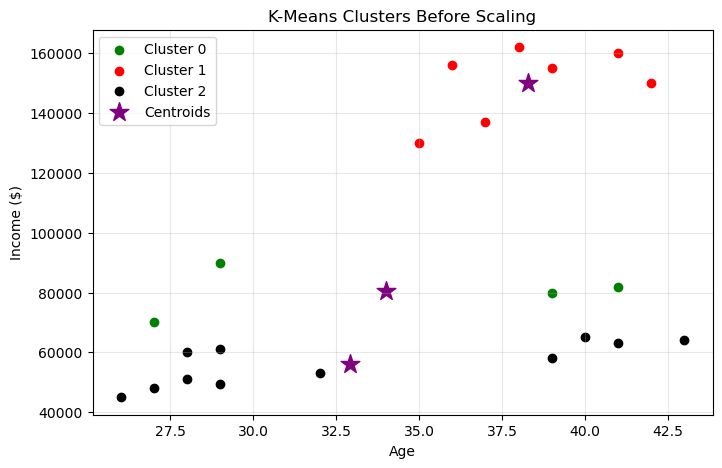

In [7]:
# Visualize the clusters before scaling
plt.figure(figsize=(8, 5))
for cluster_id, color in zip(range(3), ['green', 'red', 'black']):
    part = df[df.cluster == cluster_id]
    plt.scatter(part.Age, part['Income($)'], color=color, label=f'Cluster {cluster_id}')
plt.scatter(km.cluster_centers_[:, 0], km.cluster_centers_[:, 1],
            color='purple', marker='*', s=200, label='Centroids')
plt.xlabel('Age')
plt.ylabel('Income ($)')
plt.title('K-Means Clusters Before Scaling')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

The clusters may be separated mainly by income because income values are much larger than age values. K-Means uses Euclidean distance, so a feature with a larger numerical scale can dominate the distance calculation. **Feature scaling** gives Age and Income a comparable influence.

<h4 style='color:purple'>Preprocessing using min max scaler</h4>


**Min–Max scaling** squeezes every feature into the range $[0, 1]$:

$$x' = \frac{x - x_{\min}}{x_{\max} - x_{\min}}$$

**Worked example** for Rob (Age 27, Income 70,000). Age range is 26 → 43, Income range is 45,000 → 162,000:

In [8]:
# Apply Min-Max scaling to Age and Income
scaler = MinMaxScaler()
df[['Income($)', 'Age']] = scaler.fit_transform(df[['Income($)', 'Age']])

print("Scaled feature values:")
display(df[['Age', 'Income($)']].head())

Scaled feature values:


,Age,Income($)
0,0.058824,0.213675
1,0.176471,0.384615
2,0.176471,0.136752
3,0.117647,0.128205
4,0.941176,0.897436


In [9]:
df.head()

,Name,Age,Income($),cluster
0,Rob,0.058824,0.213675,0
1,Michael,0.176471,0.384615,0
2,Mohan,0.176471,0.136752,2
3,Ismail,0.117647,0.128205,2
4,Kory,0.941176,0.897436,1


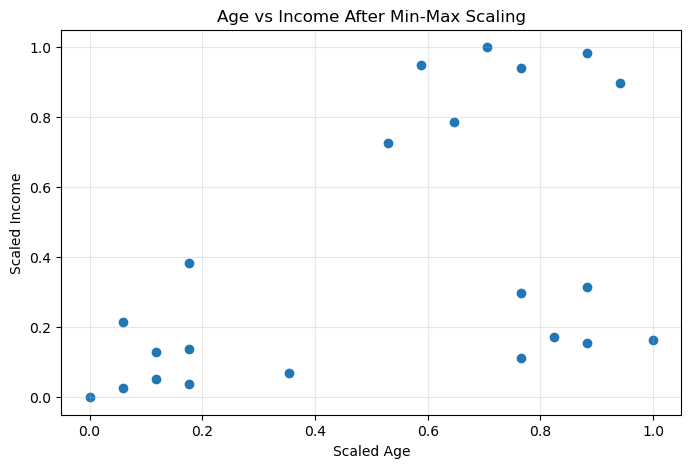

In [10]:
plt.figure(figsize=(8, 5))
plt.scatter(df.Age, df['Income($)'])
plt.xlabel('Scaled Age')
plt.ylabel('Scaled Income')
plt.title('Age vs Income After Min-Max Scaling')
plt.grid(True, alpha=0.3)
plt.show()

In [11]:
# Train K-Means on the scaled features
km = KMeans(n_clusters=3, random_state=42, n_init=10)
y_predicted = km.fit_predict(df[['Age', 'Income($)']])
y_predicted

c:\Users\Moulya\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


array([1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2],
      dtype=int32)

In [12]:
df['cluster'] = y_predicted
display(df.head())

,Name,Age,Income($),cluster
0,Rob,0.058824,0.213675,1
1,Michael,0.176471,0.384615,1
2,Mohan,0.176471,0.136752,1
3,Ismail,0.117647,0.128205,1
4,Kory,0.941176,0.897436,0


In [13]:
# Centroids in the scaled feature space
km.cluster_centers_

array([[0.72268908, 0.8974359 ],
       [0.1372549 , 0.11633428],
       [0.85294118, 0.2022792 ]])

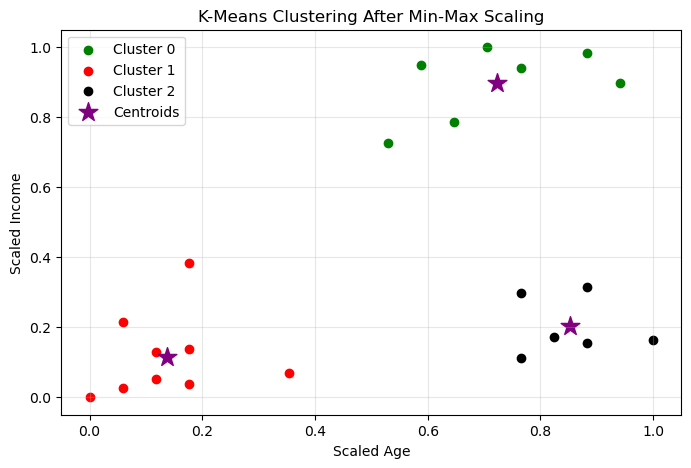

In [14]:
# Plot the three clusters and their centroids
plt.figure(figsize=(8, 5))
cluster_colors = ['green', 'red', 'black']
for cluster_id, color in zip(range(3), cluster_colors):
    part = df[df.cluster == cluster_id]
    plt.scatter(part.Age, part['Income($)'], color=color, label=f'Cluster {cluster_id}')
plt.scatter(km.cluster_centers_[:, 0], km.cluster_centers_[:, 1],
            color='purple', marker='*', s=200, label='Centroids')
plt.xlabel('Scaled Age')
plt.ylabel('Scaled Income')
plt.title('K-Means Clustering After Min-Max Scaling')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

<h4 style='color:purple'>Elbow Plot</h4>

[![Picture1.png](https://i.postimg.cc/k5xhZXvY/Picture1.png)](https://postimg.cc/3yxB0h62)

# SSE and silhouette scores

We calculate **WCSS (inertia)** and the **silhouette score** for different values of K. The elbow method looks for a point where the decrease in WCSS starts slowing down. The silhouette score measures how well-separated the clusters are; a higher score is generally better.

In [15]:
# Calculate WCSS and silhouette scores for K = 2 to 10
X_minmax = df[['Age', 'Income($)']].to_numpy(dtype=float)
k_range = range(2, 11)
sse = []
silhouette_scores = []

for k in k_range:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_minmax)
    sse.append(model.inertia_)
    silhouette_scores.append(silhouette_score(X_minmax, labels))

print("K values:", list(k_range))
print("WCSS:", np.round(sse, 3))
print("Silhouette scores:", np.round(silhouette_scores, 3))

c:\Users\Moulya\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\Moulya\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\Moulya\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\Moulya\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Wi

K values: [2, 3, 4, 5, 6, 7, 8, 9, 10]
WCSS: [2.091 0.475 0.349 0.282 0.224 0.169 0.133 0.104 0.081]
Silhouette scores: [0.56  0.713 0.626 0.468 0.429 0.452 0.358 0.33  0.302]


c:\Users\Moulya\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\Moulya\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\Moulya\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


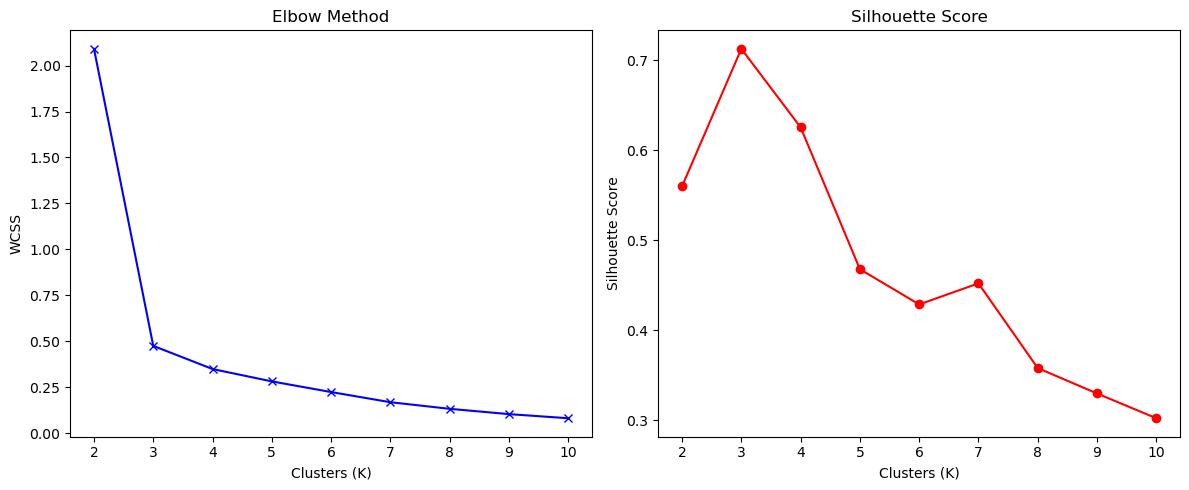

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

ax[0].plot(list(k_range), sse, 'bx-')
ax[0].set(title='Elbow Method', xlabel='Clusters (K)', ylabel='WCSS')
ax[0].set_xticks(list(k_range))

ax[1].plot(list(k_range), silhouette_scores, 'ro-')
ax[1].set(title='Silhouette Score', xlabel='Clusters (K)', ylabel='Silhouette Score')
ax[1].set_xticks(list(k_range))

plt.tight_layout()
plt.show()

# load the dataset

In [17]:
# Load the same income dataset for the from-scratch implementation
df = pd.read_csv("income - income.csv")
print("Dataset shape:", df.shape)
display(df.head())
display(df.describe())

# Use only numerical features. Name is not used for clustering.
X = df[['Age', 'Income($)']].to_numpy(dtype=float)

Dataset shape: (22, 3)


,Name,Age,Income($)
0,Rob,27,70000
1,Michael,29,90000
2,Mohan,29,61000
3,Ismail,28,60000
4,Kory,42,150000


,Age,Income($)
count,22.000000,22.000000
mean,34.818182,90431.818182
std,5.901060,43505.964412
min,26.000000,45000.000000
25%,29.000000,58500.000000
50%,36.500000,67500.000000
75%,39.750000,135250.000000
max,43.000000,162000.000000


## Why Z-score normalization is necessary

K-Means calculates Euclidean distances between data points and centroids. Income values are in thousands while Age values are in tens. Without scaling, income would have a much greater effect on the distance. Z-score normalization transforms each feature to have approximately mean 0 and standard deviation 1, allowing both features to contribute more fairly.

In [18]:
# Z-score normalization
X_scaled = (X - X.mean(axis=0)) / X.std(axis=0)

print("Standardized Data (first five rows):\\n", np.round(X_scaled[:5], 3))
print("Feature means:", X_scaled.mean(axis=0))
print("Feature standard deviations:", X_scaled.std(axis=0))

Standardized Data (first five rows):\n [[-1.356 -0.481]
 [-1.009 -0.01 ]
 [-1.009 -0.692]
 [-1.183 -0.716]
 [ 1.246  1.401]]
Feature means: [-3.48206312e-16  1.05975834e-16]
Feature standard deviations: [1. 1.]


# Define the custom K-Means algorithm

In [19]:
# Define WCSS and the custom K-Means algorithm using NumPy only
def calculate_wcss(X, centroids, labels):
    """Calculate within-cluster sum of squared distances."""
    total = 0.0
    for cluster_id in range(len(centroids)):
        points = X[labels == cluster_id]
        if len(points) > 0:
            total += np.sum((points - centroids[cluster_id]) ** 2)
    return float(total)


def kmeans(X, k, max_iters=100, n_init=10, seed=42):
    """Return best centroids, labels, WCSS and iteration count."""
    X = np.asarray(X, dtype=float)
    if k < 1 or k > len(X):
        raise ValueError("k must be between 1 and the number of samples")

    rng = np.random.default_rng(seed)
    best_centroids, best_labels = None, None
    best_wcss = np.inf
    best_iterations = 0

    for _ in range(n_init):
        # Initialise centroids by selecting distinct data points
        centroids = X[rng.choice(len(X), size=k, replace=False)].copy()

        for iteration in range(1, max_iters + 1):
            # Assignment step: find the nearest centroid
            distances = np.linalg.norm(X[:, np.newaxis, :] - centroids[np.newaxis, :, :], axis=2)
            labels = np.argmin(distances, axis=1)

            # Update step: calculate the mean of each cluster
            new_centroids = centroids.copy()
            for cluster_id in range(k):
                cluster_points = X[labels == cluster_id]
                if len(cluster_points) > 0:
                    new_centroids[cluster_id] = cluster_points.mean(axis=0)

            # Stop when centroids no longer change
            if np.allclose(centroids, new_centroids):
                centroids = new_centroids
                break
            centroids = new_centroids

        # Reassign using final centroids and calculate WCSS
        distances = np.linalg.norm(X[:, np.newaxis, :] - centroids[np.newaxis, :, :], axis=2)
        labels = np.argmin(distances, axis=1)
        wcss = calculate_wcss(X, centroids, labels)

        if wcss < best_wcss:
            best_centroids = centroids.copy()
            best_labels = labels.copy()
            best_wcss = wcss
            best_iterations = iteration

    return best_centroids, best_labels, best_wcss, best_iterations


# Bonus: silhouette score implemented using NumPy
def silhouette_score_scratch(X, labels):
    X = np.asarray(X, dtype=float)
    labels = np.asarray(labels)
    unique_labels = np.unique(labels)
    if len(unique_labels) < 2 or len(unique_labels) >= len(X):
        raise ValueError("Silhouette score requires 2 to n_samples-1 clusters")

    # Pairwise Euclidean distance matrix
    distances = np.linalg.norm(X[:, None, :] - X[None, :, :], axis=2)
    scores = []

    for i in range(len(X)):
        own_cluster = labels == labels[i]
        own_cluster[i] = False
        a = distances[i, own_cluster].mean() if np.any(own_cluster) else 0.0

        other_means = [
            distances[i, labels == other].mean()
            for other in unique_labels if other != labels[i]
        ]
        b = min(other_means)
        denominator = max(a, b)
        scores.append((b - a) / denominator if denominator > 0 else 0.0)

    return float(np.mean(scores))

In [20]:
# Run custom K-Means with K = 3
k = 3
centroids, labels, wcss, iterations = kmeans(X_scaled, k, max_iters=100, n_init=10, seed=42)

df['Cluster'] = labels
print("Clustered data:")
display(df.head())
print("Centroids (standardized feature space):\\n", np.round(centroids, 3))
print("WCSS:", round(wcss, 3))
print("Iterations:", iterations)
print("Scratch silhouette score:", round(silhouette_score_scratch(X_scaled, labels), 4))

Clustered data:


,Name,Age,Income($),Cluster
0,Rob,27,70000,0
1,Michael,29,90000,0
2,Mohan,29,61000,0
3,Ismail,28,60000,0
4,Kory,42,150000,1


Centroids (standardized feature space):\n [[-1.125 -0.749]
 [ 0.601  1.401]
 [ 0.986 -0.512]]
WCSS: 3.889
Iterations: 4
Scratch silhouette score: 0.712


<h4 style='color:purple'>Exercise</h4>

## Exercise: Compare custom K-Means with scikit-learn on the Income Dataset

### Objective
Apply K-Means clustering to the uploaded **income - income.csv** dataset in two ways:
1. Using the custom NumPy implementation written above.
2. Using scikit-learn's `KMeans` class.

### Step 1 — Prepare the data
Use **Age** and **Income($)** as features. Do not use `Name` because it is an identifier, not a numerical feature. The dataset does not contain ground-truth cluster labels, so external metrics such as ARI and NMI cannot be calculated meaningfully.

### Step 2 — Compare models
For K = 2 to 10, calculate WCSS and silhouette score for both implementations. Plot both sets of scores. Select a suitable K by considering the elbow curve, silhouette score and the usefulness of the resulting groups.

### Step 3 — Evaluate at K = 3
Compare WCSS and silhouette score for the custom and scikit-learn models. Their cluster numbers may be labelled differently, but the actual groupings can still be equivalent.

### Note
The custom implementation uses Z-score standardized features. The scikit-learn implementation below uses the same standardized data to ensure a fair comparison.

c:\Users\Moulya\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\Moulya\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\Moulya\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\Moulya\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Wi

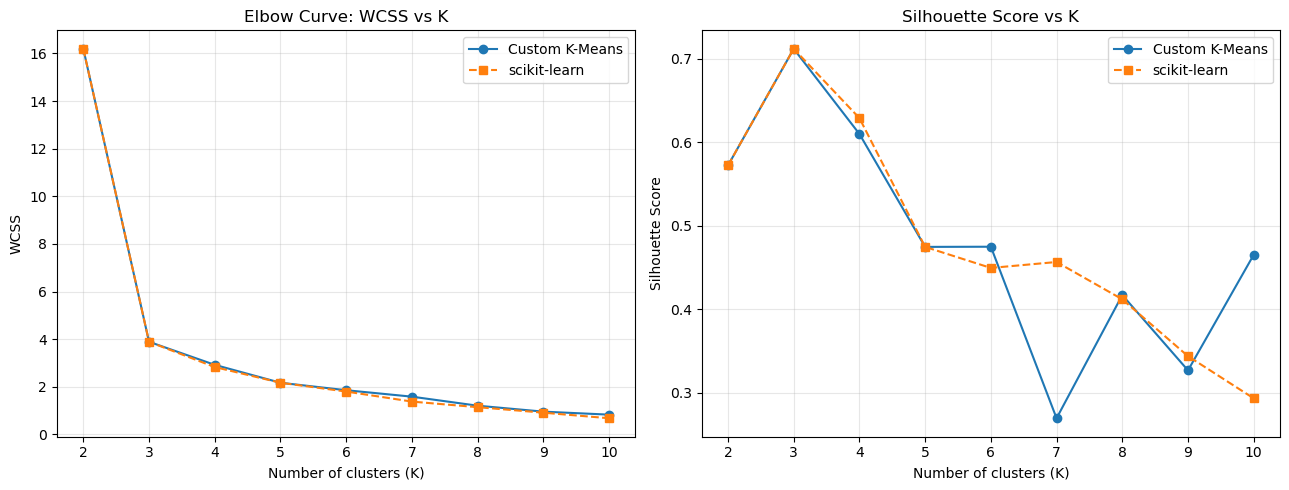

c:\Users\Moulya\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


,Metric,Custom K-Means,scikit-learn KMeans
0,WCSS / Inertia,3.8893,3.8893
1,Silhouette Score,0.7120,0.7120


Custom K-Means centroids:\n [[-1.125 -0.749]
 [ 0.601  1.401]
 [ 0.986 -0.512]]
scikit-learn centroids:\n [[ 0.601  1.401]
 [-1.125 -0.749]
 [ 0.986 -0.512]]
Custom K-Means iterations: 4
scikit-learn iterations: 3
Custom silhouette: 0.71199
sklearn silhouette: 0.71199
\nConclusion:
Both implementations perform K-Means clustering on the same standardized Age and Income features.
Small differences may occur because the initial centroid choices and convergence paths can differ.
Use the elbow and silhouette plots above to justify the final choice of K.


In [21]:
# Compare custom K-Means and scikit-learn for K = 2 to 10
k_values = range(2, 11)
scratch_wcss, sklearn_wcss = [], []
scratch_silhouette, sklearn_silhouette = [], []

for current_k in k_values:
    # Custom NumPy implementation
    c_scratch, labels_scratch, wcss_scratch, iters_scratch = kmeans(
        X_scaled, current_k, max_iters=100, n_init=10, seed=42
    )
    scratch_wcss.append(wcss_scratch)
    scratch_silhouette.append(silhouette_score_scratch(X_scaled, labels_scratch))

    # scikit-learn implementation
    model = KMeans(n_clusters=current_k, n_init=10, random_state=42)
    labels_model = model.fit_predict(X_scaled)
    sklearn_wcss.append(model.inertia_)
    sklearn_silhouette.append(silhouette_score(X_scaled, labels_model))

# Plot WCSS and silhouette scores for both implementations
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(list(k_values), scratch_wcss, 'o-', label='Custom K-Means')
axes[0].plot(list(k_values), sklearn_wcss, 's--', label='scikit-learn')
axes[0].set_title('Elbow Curve: WCSS vs K')
axes[0].set_xlabel('Number of clusters (K)')
axes[0].set_ylabel('WCSS')
axes[0].set_xticks(list(k_values))
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(list(k_values), scratch_silhouette, 'o-', label='Custom K-Means')
axes[1].plot(list(k_values), sklearn_silhouette, 's--', label='scikit-learn')
axes[1].set_title('Silhouette Score vs K')
axes[1].set_xlabel('Number of clusters (K)')
axes[1].set_ylabel('Silhouette Score')
axes[1].set_xticks(list(k_values))
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Compare the two algorithms at K = 3
k = 3
centroids_scratch, labels_scratch, wcss_scratch, iters_scratch = kmeans(
    X_scaled, k, max_iters=100, n_init=10, seed=42
)
model = KMeans(n_clusters=k, n_init=10, random_state=42)
labels_sklearn = model.fit_predict(X_scaled)

comparison = pd.DataFrame({
    'Metric': ['WCSS / Inertia', 'Silhouette Score'],
    'Custom K-Means': [
        wcss_scratch,
        silhouette_score_scratch(X_scaled, labels_scratch)
    ],
    'scikit-learn KMeans': [
        model.inertia_,
        silhouette_score(X_scaled, labels_sklearn)
    ]
})
display(comparison.round(4))

print("Custom K-Means centroids:\\n", np.round(centroids_scratch, 3))
print("scikit-learn centroids:\\n", np.round(model.cluster_centers_, 3))
print("Custom K-Means iterations:", iters_scratch)
print("scikit-learn iterations:", model.n_iter_)

# Verify the bonus silhouette implementation against scikit-learn
print("Custom silhouette:", round(silhouette_score_scratch(X_scaled, labels_scratch), 5))
print("sklearn silhouette:", round(silhouette_score(X_scaled, labels_scratch), 5))

print("\\nConclusion:")
print("Both implementations perform K-Means clustering on the same standardized Age and Income features.")
print("Small differences may occur because the initial centroid choices and convergence paths can differ.")
print("Use the elbow and silhouette plots above to justify the final choice of K.")